In [5]:

# LOADING THE DATASET & INITIAL INSPECTION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine

#upload database
wine = load_wine()
X = pd.DataFrame(data=wine.data, columns=wine.feature_names)
y = pd.Series(data=wine.target, name='target')

print("=== WINE DATASET OVERVIEW ===")
print(f"X shape (Samples, Features): {X.shape}")
print(f"\nTarget Distribution (Class Counts):\n{y.value_counts()}")

=== WINE DATASET OVERVIEW ===
X shape (Samples, Features): (178, 13)

Target Distribution (Class Counts):
target
1    71
0    59
2    48
Name: count, dtype: int64


In [6]:

# 2. DATA QUALITY CONTROL

print("=== DATA QUALITY CONTROL ===")
print(f"Missing values in X: {X.isnull().sum().sum()}")
print(f"Duplicate rows in X: {X.duplicated().sum()}")

=== DATA QUALITY CONTROL ===
Missing values in X: 0
Duplicate rows in X: 0


=== DESCRIPTIVE STATISTICS ===


,mean,std,min,Q1,median,Q3,max
alcohol,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


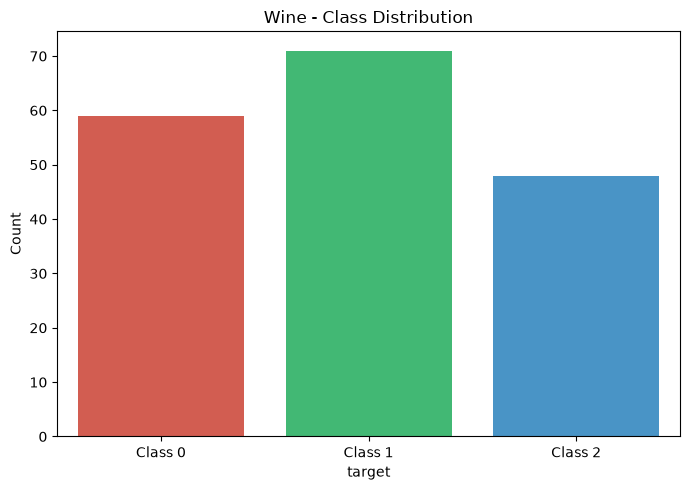

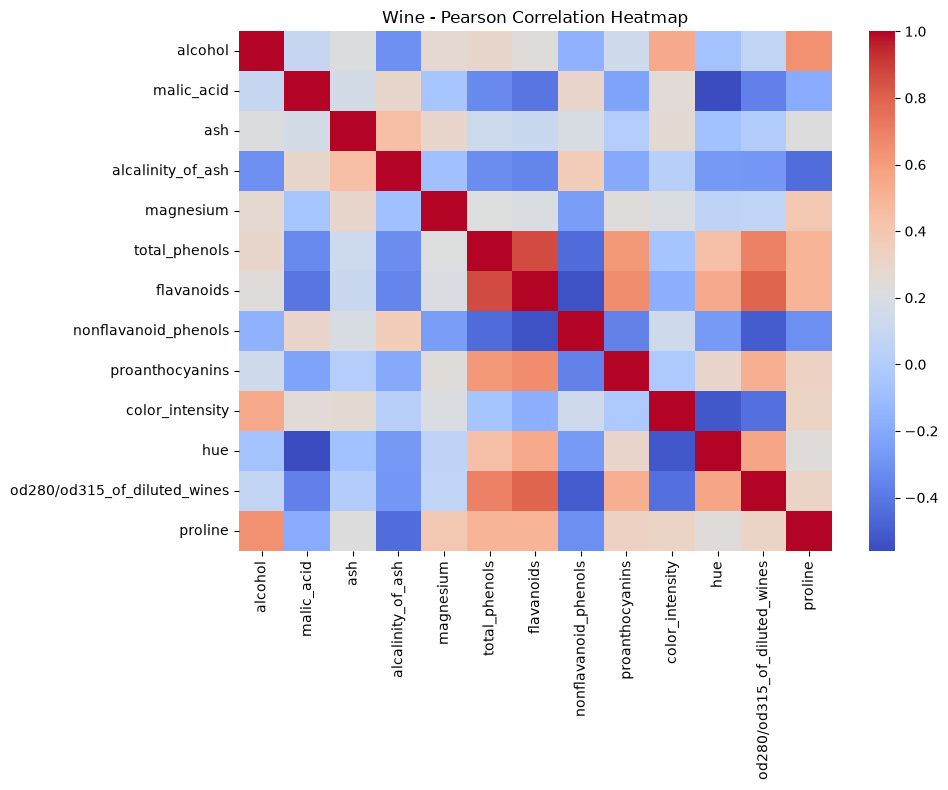


Top 3 Strongest Unique Feature Pairs (Absolute Correlation):
total_phenols                 flavanoids                      0.864564
od280/od315_of_diluted_wines  flavanoids                      0.787194
total_phenols                 od280/od315_of_diluted_wines    0.699949
dtype: float64


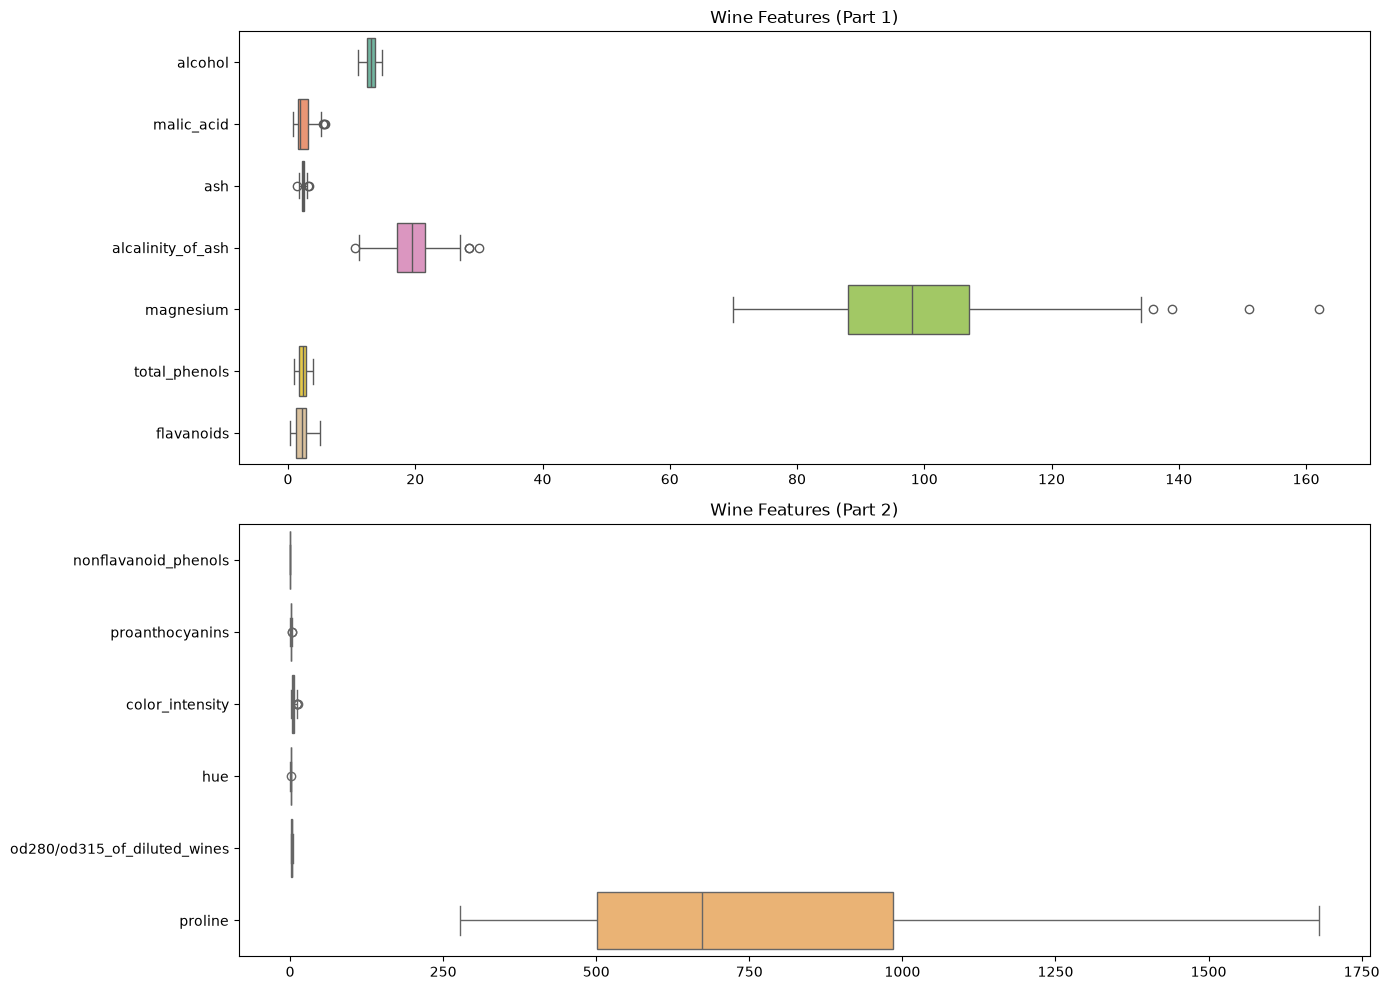

In [12]:

# EXPLORATORY DATA ANALYSIS 
import matplotlib.pyplot as plt
import seaborn as sns

# Descriptive Statistics
print("=== DESCRIPTIVE STATISTICS ===")
desc_stats = X.describe().T
desc_stats['median'] = X.median()
desc_stats['Q1'] = X.quantile(0.25)
desc_stats['Q3'] = X.quantile(0.75)
display(desc_stats[['mean', 'std', 'min', 'Q1', 'median', 'Q3', 'max']])

#  Class Distribution
plt.figure(figsize=(7, 5))
sns.countplot(x=y, hue=y, palette=['#e74c3c', '#2ecc71', '#3498db'], legend=False)
plt.title('Wine - Class Distribution')
plt.xticks(ticks=[0, 1, 2], labels=['Class 0', 'Class 1', 'Class 2'])
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('figures/wine_class_distribution.png')
plt.show()

# Pearson Correlation Heatmap & Top 3 Pairs
plt.figure(figsize=(10, 8))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, fmt=".2f")
plt.title('Wine - Pearson Correlation Heatmap')
plt.tight_layout()
plt.savefig('figures/wine_correlation_heatmap.png')
plt.show()

corr_pairs = corr_matrix.abs().unstack()
corr_pairs = corr_pairs[corr_pairs < 1.0].sort_values(ascending=False).drop_duplicates()
print("\nTop 3 Strongest Unique Feature Pairs (Absolute Correlation):")
print(corr_pairs.head(3))

# Feature Boxplots (Grouped for Enhanced Readability)
# Split features into two panels due to significant differences in feature scales
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
sns.boxplot(data=X.iloc[:, :7], orient='h', ax=axes[0], palette='Set2')
axes[0].set_title('Wine Features (Part 1)')

sns.boxplot(data=X.iloc[:, 7:], orient='h', ax=axes[1], palette='Set3')
axes[1].set_title('Wine Features (Part 2)')

plt.tight_layout()
plt.savefig('figures/wine_boxplots.png')
plt.show()

In [13]:

#  SPLITTING THE DATASET
from sklearn.model_selection import train_test_split

SEEDS = [42, 52, 62]

# Fixed 20% Test set (36 samples)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

splits = {}
split_summary_rows = []

for seed in SEEDS:
   # 12.5% of the remaining 80% data = 10% of total dataset (Validation)
    X_tr, X_v, y_tr, y_v = train_test_split(
        X_train_val, y_train_val, test_size=0.125, stratify=y_train_val, random_state=seed
    )
    
    splits[seed] = {
        'X_train': X_tr, 'X_val': X_v, 'X_test': X_test,
        'y_train': y_tr, 'y_val': y_v, 'y_test': y_test
    }
    
    for name, sub_x, sub_y in [('Train', X_tr, y_tr), ('Validation', X_v, y_v), ('Test', X_test, y_test)]:
        c_counts = sub_y.value_counts().to_dict()
        split_summary_rows.append({
            'Seed': seed, 'Subset': name,
            'Total Samples': len(sub_x),
            'Percentage (%)': round(len(sub_x) / len(X) * 100, 2),
            'Class 0': c_counts.get(0, 0),
            'Class 1': c_counts.get(1, 0),
            'Class 2': c_counts.get(2, 0)
        })

split_summary_df = pd.DataFrame(split_summary_rows)
print("=== WINE SPLIT SUMMARY TABLE (9 ROWS) ===")
print(split_summary_df.to_string(index=False))

=== WINE SPLIT SUMMARY TABLE (9 ROWS) ===
 Seed     Subset  Total Samples  Percentage (%)  Class 0  Class 1  Class 2
   42      Train            124           69.66       41       50       33
   42 Validation             18           10.11        6        7        5
   42       Test             36           20.22       12       14       10
   52      Train            124           69.66       41       50       33
   52 Validation             18           10.11        6        7        5
   52       Test             36           20.22       12       14       10
   62      Train            124           69.66       41       50       33
   62 Validation             18           10.11        6        7        5
   62       Test             36           20.22       12       14       10


In [14]:

#  SUPERVISED LEARNING & EVALUATION

from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'NaiveBayes': GaussianNB()
}

results = []

for seed in SEEDS:
    X_tr = splits[seed]['X_train']
    y_tr = splits[seed]['y_train']
    X_va = splits[seed]['X_val']
    y_va = splits[seed]['y_val']

    # Standardization
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_va_scaled = scaler.transform(X_va)

    for name, model in models.items():
        model.fit(X_tr_scaled, y_tr)
        y_pred = model.predict(X_va_scaled)
        
        # Multi-class ROC-AUC calculation (One-vs-Rest with macro average)
        if hasattr(model, "predict_proba"):
            y_proba = model.predict_proba(X_va_scaled)
            roc_auc = roc_auc_score(y_va, y_proba, multi_class='ovr')
        else:
            roc_auc = np.nan

        results.append({
            'Seed': seed,
            'Model': name,
            'Accuracy': round(accuracy_score(y_va, y_pred), 4),
            'Precision': round(precision_score(y_va, y_pred, average='weighted'), 4),
            'Recall': round(recall_score(y_va, y_pred, average='weighted'), 4),
            'F1-Score': round(f1_score(y_va, y_pred, average='weighted'), 4),
            'ROC-AUC': round(roc_auc, 4)
        })

results_df = pd.DataFrame(results)
print("=== WINE MODEL EVALUATION RESULTS ===")
print(results_df.to_string(index=False))


=== WINE MODEL EVALUATION RESULTS ===
 Seed        Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
   42 DecisionTree    0.9444     0.9514  0.9444    0.9438   0.9571
   42          KNN    1.0000     1.0000  1.0000    1.0000   1.0000
   42   NaiveBayes    1.0000     1.0000  1.0000    1.0000   1.0000
   52 DecisionTree    0.9444     0.9537  0.9444    0.9448   0.9634
   52          KNN    1.0000     1.0000  1.0000    1.0000   1.0000
   52   NaiveBayes    0.9444     0.9537  0.9444    0.9448   1.0000
   62 DecisionTree    0.8889     0.8958  0.8889    0.8877   0.9098
   62          KNN    0.9444     0.9537  0.9444    0.9448   1.0000
   62   NaiveBayes    0.9444     0.9514  0.9444    0.9438   1.0000


In [15]:

#  UNSUPERVISED LEARNING: K-MEANS CLUSTERING
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

scaler_full = StandardScaler()
X_scaled_full = scaler_full.fit_transform(X)

# Set n_clusters=3 because the Wine dataset naturally contains 3 distinct target classes (Class 0, Class 1, Class 2)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled_full)

ari = adjusted_rand_score(y, cluster_labels)
sil = silhouette_score(X_scaled_full, cluster_labels)

kmeans_results = pd.DataFrame([{
    'Dataset': 'Wine',
    'K': 3,
    'Adjusted Rand Index (ARI)': round(ari, 4),
    'Silhouette Score': round(sil, 4)
}])

print("\n=== K-MEANS CLUSTERING RESULTS (K=3) ===")
print(kmeans_results.to_string(index=False))


=== K-MEANS CLUSTERING RESULTS (K=3) ===
Dataset  K  Adjusted Rand Index (ARI)  Silhouette Score
   Wine  3                     0.8975            0.2849


In [16]:

# MODEL TRAINING & VALIDATION (66 RUNS)

from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

classifier_runs = []

# Grid
dt_depths = [2, 3, 5, 10, None]
knn_neighbors = [1, 3, 5, 7, 11]

for seed, data_split in splits.items():
    X_tr = data_split['X_train']
    y_tr = data_split['y_train']
    X_va = data_split['X_val']
    y_va = data_split['y_val']
    
    # Preprocessing (Train-only fit)
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_va_scaled = scaler.transform(X_va)
    
    representations = {
        'unscaled': (X_tr, X_va),
        'scaled': (X_tr_scaled, X_va_scaled)
    }
    
    for rep_name, (X_t, X_v) in representations.items():
        
        # Decision Trees 
        for depth in dt_depths:
            run_id = f"wine_dt_{rep_name}_d{depth}_s{seed}"
            model = DecisionTreeClassifier(max_depth=depth, random_state=seed)
            model.fit(X_t, y_tr)
            
            # Predict & Evaluate
            preds = model.predict(X_v)
            probs = model.predict_proba(X_v)
            
            classifier_runs.append({
                'run_id': run_id, 'dataset': 'Wine', 'seed': seed,
                'algorithm': 'DecisionTree', 'representation': rep_name,
                'parameter': f"max_depth={depth}",
                'train_acc': round(accuracy_score(y_tr, model.predict(X_t)), 4),
                'val_acc': round(accuracy_score(y_va, preds), 4),
                'val_precision': round(precision_score(y_va, preds, average='macro', zero_division=0), 4),
                'val_recall': round(recall_score(y_va, preds, average='macro', zero_division=0), 4),
                'val_f1': round(f1_score(y_va, preds, average='macro', zero_division=0), 4),
                'val_roc_auc': round(roc_auc_score(y_va, probs, multi_class='ovr', average='macro'), 4)
            })
            
        #  KNN 
        for k in knn_neighbors:
            run_id = f"wine_knn_{rep_name}_k{k}_s{seed}"
            model = KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')
            model.fit(X_t, y_tr)
            
            preds = model.predict(X_v)
            probs = model.predict_proba(X_v)
            
            classifier_runs.append({
                'run_id': run_id, 'dataset': 'Wine', 'seed': seed,
                'algorithm': 'KNN', 'representation': rep_name,
                'parameter': f"n_neighbors={k}",
                'train_acc': round(accuracy_score(y_tr, model.predict(X_t)), 4),
                'val_acc': round(accuracy_score(y_va, preds), 4),
                'val_precision': round(precision_score(y_va, preds, average='macro', zero_division=0), 4),
                'val_recall': round(recall_score(y_va, preds, average='macro', zero_division=0), 4),
                'val_f1': round(f1_score(y_va, preds, average='macro', zero_division=0), 4),
                'val_roc_auc': round(roc_auc_score(y_va, probs, multi_class='ovr', average='macro'), 4)
            })
            
        # Naive Bayes 
        run_id = f"wine_nb_{rep_name}_default_s{seed}"
        model = GaussianNB()
        model.fit(X_t, y_tr)
        
        preds = model.predict(X_v)
        probs = model.predict_proba(X_v)
        
        classifier_runs.append({
            'run_id': run_id, 'dataset': 'Wine', 'seed': seed,
            'algorithm': 'GaussianNB', 'representation': rep_name,
            'parameter': 'default',
            'train_acc': round(accuracy_score(y_tr, model.predict(X_t)), 4),
            'val_acc': round(accuracy_score(y_va, preds), 4),
            'val_precision': round(precision_score(y_va, preds, average='macro', zero_division=0), 4),
            'val_recall': round(recall_score(y_va, preds, average='macro', zero_division=0), 4),
            'val_f1': round(f1_score(y_va, preds, average='macro', zero_division=0), 4),
            'val_roc_auc': round(roc_auc_score(y_va, probs, multi_class='ovr', average='macro'), 4)
        })

df_classifier_runs = pd.DataFrame(classifier_runs)
print(f"Total Classifier Runs Completed: {len(df_classifier_runs)}") # 66 çıkmalı!
display(df_classifier_runs.head())

Total Classifier Runs Completed: 66


,run_id,dataset,seed,algorithm,representation,parameter,train_acc,val_acc,val_precision,val_recall,val_f1,val_roc_auc
0,wine_dt_unscaled_d2_s42,Wine,42,DecisionTree,unscaled,max_depth=2,0.9355,0.8333,0.8631,0.8111,0.8175,0.9106
1,wine_dt_unscaled_d3_s42,Wine,42,DecisionTree,unscaled,max_depth=3,0.9919,0.9444,0.9583,0.9444,0.9475,0.9686
2,wine_dt_unscaled_d5_s42,Wine,42,DecisionTree,unscaled,max_depth=5,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
3,wine_dt_unscaled_d10_s42,Wine,42,DecisionTree,unscaled,max_depth=10,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
4,wine_dt_unscaled_dNone_s42,Wine,42,DecisionTree,unscaled,max_depth=None,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571


=== WINE CLASSIFIER SUMMARY TABLE (22 CONFIGURATIONS) ===


,dataset,algorithm,representation,parameter,mean_train_acc,std_train_acc,mean_val_acc,std_val_acc,mean_val_precision,std_val_precision,mean_val_recall,std_val_recall,mean_val_f1,std_val_f1,mean_val_roc_auc,std_val_roc_auc
0,Wine,DecisionTree,scaled,max_depth=10,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457
1,Wine,DecisionTree,scaled,max_depth=2,0.9355,0.0081,0.8518,0.0321,0.8723,0.0214,0.8487,0.0495,0.8481,0.0365,0.9050,0.0219
2,Wine,DecisionTree,scaled,max_depth=3,0.9919,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9611,0.0431
3,Wine,DecisionTree,scaled,max_depth=5,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457
4,Wine,DecisionTree,scaled,max_depth=None,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457
5,Wine,DecisionTree,unscaled,max_depth=10,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457
6,Wine,DecisionTree,unscaled,max_depth=2,0.9355,0.0081,0.8518,0.0321,0.8723,0.0214,0.8487,0.0495,0.8481,0.0365,0.9050,0.0219
7,Wine,DecisionTree,unscaled,max_depth=3,0.9919,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9611,0.0431
8,Wine,DecisionTree,unscaled,max_depth=5,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457
9,Wine,DecisionTree,unscaled,max_depth=None,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457



SELECTED BEST CONFIGURATION FOR WINE DATASET:
Algorithm: KNN
Representation: scaled
Parameter: n_neighbors=11
Mean Validation Macro-F1: 0.9814 ± 0.0323



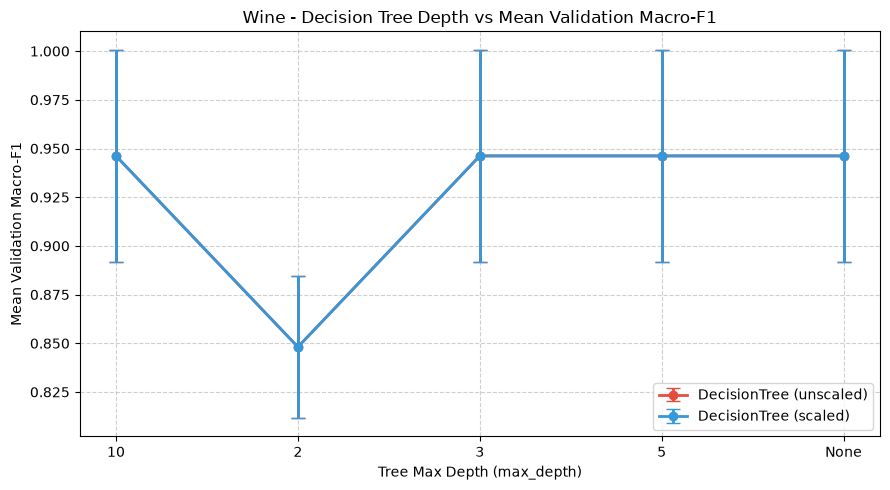

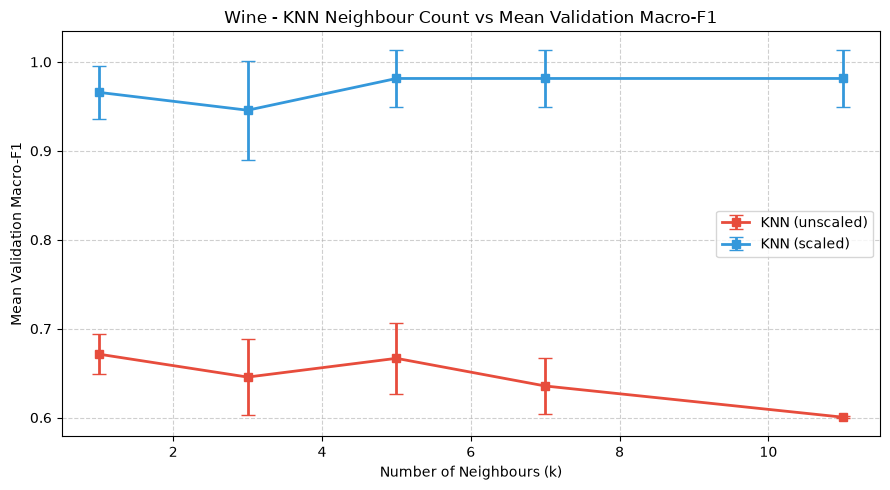

In [18]:

# TABLE & PARAMETER FIGURES (WINE)

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#  22 Konfigürasyonluk Özet Tabloyu Hesaplama
classifier_summary = df_classifier_runs.groupby(
    ['dataset', 'algorithm', 'representation', 'parameter']
).agg(
    mean_train_acc=('train_acc', 'mean'),
    std_train_acc=('train_acc', lambda x: x.std(ddof=1)),
    mean_val_acc=('val_acc', 'mean'),
    std_val_acc=('val_acc', lambda x: x.std(ddof=1)),
    mean_val_precision=('val_precision', 'mean'),
    std_val_precision=('val_precision', lambda x: x.std(ddof=1)),
    mean_val_recall=('val_recall', 'mean'),
    std_val_recall=('val_recall', lambda x: x.std(ddof=1)),
    mean_val_f1=('val_f1', 'mean'),
    std_val_f1=('val_f1', lambda x: x.std(ddof=1)),
    mean_val_roc_auc=('val_roc_auc', 'mean'),
    std_val_roc_auc=('val_roc_auc', lambda x: x.std(ddof=1))
).reset_index()

for col in classifier_summary.columns:
    if col not in ['dataset', 'algorithm', 'representation', 'parameter']:
        classifier_summary[col] = classifier_summary[col].round(4)

print("=== WINE CLASSIFIER SUMMARY TABLE (22 CONFIGURATIONS) ===")
display(classifier_summary)

#  En İyi Konfigürasyon Seçimi
best_config = classifier_summary.sort_values(
    by=['mean_val_f1', 'mean_val_acc', 'std_val_f1'], 
    ascending=[False, False, True]
).iloc[0]

print("\n" + "="*50)
print(f"SELECTED BEST CONFIGURATION FOR WINE DATASET:")
print(f"Algorithm: {best_config['algorithm']}")
print(f"Representation: {best_config['representation']}")
print(f"Parameter: {best_config['parameter']}")
print(f"Mean Validation Macro-F1: {best_config['mean_val_f1']:.4f} ± {best_config['std_val_f1']:.4f}")
print("="*50 + "\n")

#  Parametre Karşılaştırma Grafikleri (Figures)
os.makedirs('figures', exist_ok=True)

# Decision Tree Depth vs Mean Validation Macro-F1
dt_data = classifier_summary[classifier_summary['algorithm'] == 'DecisionTree'].copy()
dt_data['depth_val'] = dt_data['parameter'].str.replace('max_depth=', '')

plt.figure(figsize=(9, 5))
for rep, color in [('unscaled', '#e74c3c'), ('scaled', '#3498db')]:
    sub = dt_data[dt_data['representation'] == rep]
    plt.errorbar(
        x=sub['depth_val'], 
        y=sub['mean_val_f1'], 
        yerr=sub['std_val_f1'], 
        label=f"DecisionTree ({rep})", 
        capsize=5, marker='o', color=color, linewidth=2
    )

plt.title('Wine - Decision Tree Depth vs Mean Validation Macro-F1')
plt.xlabel('Tree Max Depth (max_depth)')
plt.ylabel('Mean Validation Macro-F1')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('figures/wine_dt_depth_comparison.png')
plt.show()

# KNN Neighbour Count vs Mean Validation Macro-F1
knn_data = classifier_summary[classifier_summary['algorithm'] == 'KNN'].copy()
knn_data['k_val'] = knn_data['parameter'].str.replace('n_neighbors=', '').astype(int)
knn_data = knn_data.sort_values(by='k_val')

plt.figure(figsize=(9, 5))
for rep, color in [('unscaled', '#e74c3c'), ('scaled', '#3498db')]:
    sub = knn_data[knn_data['representation'] == rep]
    plt.errorbar(
        x=sub['k_val'], 
        y=sub['mean_val_f1'], 
        yerr=sub['std_val_f1'], 
        label=f"KNN ({rep})", 
        capsize=5, marker='s', color=color, linewidth=2
    )

plt.title('Wine - KNN Neighbour Count vs Mean Validation Macro-F1')
plt.xlabel('Number of Neighbours (k)')
plt.ylabel('Mean Validation Macro-F1')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('figures/wine_knn_k_comparison.png')
plt.show()

=== FINAL TEST EVALUATION RESULTS (SEED 42) ===
Selected Configuration: KNN (scaled, n_neighbors=11)
Test Accuracy: 1.0000
Test Precision (Macro): 1.0000
Test Recall (Macro): 1.0000
Test F1-Score (Macro): 1.0000
Test ROC-AUC (Macro OvR): 1.0000

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00        12
     Class 1       1.00      1.00      1.00        14
     Class 2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



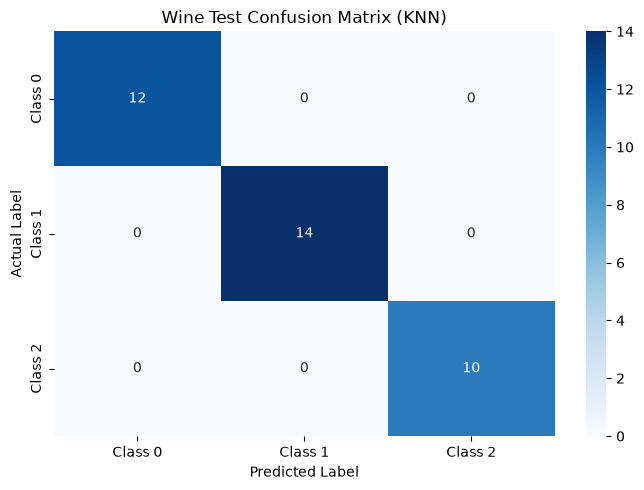

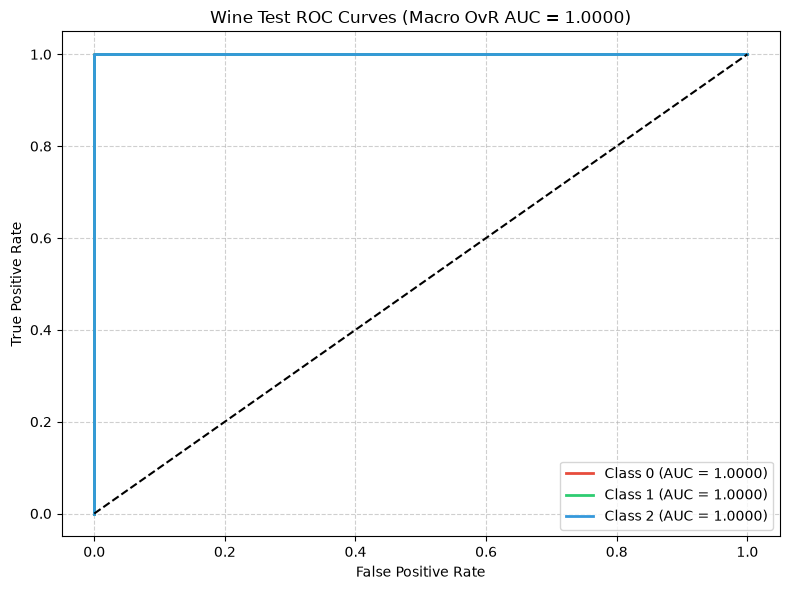

=== MANUAL METRIC VERIFICATION (FOR CLASS 0) ===
Manual Class 0 Precision: 1.0000
Manual Class 0 Recall:    1.0000
Manual Class 0 F1-Score:  1.0000


In [ ]:

# FINAL TEST EVALUATION & VISUALIZATIONS (WINE)

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report, confusion_matrix, 
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

#  Seed 42 
X_tr_42 = splits[42]['X_train']
y_tr_42 = splits[42]['y_train']
X_te_fixed = splits[42]['X_test']
y_te_fixed = splits[42]['y_test']

# Seed 42 Scaler
scaler_42 = StandardScaler()
X_tr_42_scaled = scaler_42.fit_transform(X_tr_42)
X_te_fixed_scaled = scaler_42.transform(X_te_fixed)

#  KNN (scaled, k=5 or k=11)

if best_config['algorithm'] == 'KNN':
    k_val = int(best_config['parameter'].split('=')[1])
    final_model = KNeighborsClassifier(n_neighbors=k_val, weights='uniform', metric='euclidean')
elif best_config['algorithm'] == 'DecisionTree':
    depth_str = best_config['parameter'].split('=')[1]
    depth_val = None if depth_str == 'None' else int(depth_str)
    final_model = DecisionTreeClassifier(max_depth=depth_val, random_state=42)
else:
    final_model = GaussianNB()

if best_config['representation'] == 'scaled':
    X_train_final, X_test_final = X_tr_42_scaled, X_te_fixed_scaled
else:
    X_train_final, X_test_final = X_tr_42, X_te_fixed

final_model.fit(X_train_final, y_tr_42)
y_test_pred = final_model.predict(X_test_final)
y_test_proba = final_model.predict_proba(X_test_final)

test_acc = accuracy_score(y_te_fixed, y_test_pred)
test_prec = precision_score(y_te_fixed, y_test_pred, average='macro', zero_division=0)
test_rec = recall_score(y_te_fixed, y_test_pred, average='macro', zero_division=0)
test_f1 = f1_score(y_te_fixed, y_test_pred, average='macro', zero_division=0)
test_roc_auc = roc_auc_score(y_te_fixed, y_test_proba, multi_class='ovr', average='macro')

print("=== FINAL TEST EVALUATION RESULTS (SEED 42) ===")
print(f"Selected Configuration: {best_config['algorithm']} ({best_config['representation']}, {best_config['parameter']})")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Precision (Macro): {test_prec:.4f}")
print(f"Test Recall (Macro): {test_rec:.4f}")
print(f"Test F1-Score (Macro): {test_f1:.4f}")
print(f"Test ROC-AUC (Macro OvR): {test_roc_auc:.4f}\n")

print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_te_fixed, y_test_pred, target_names=['Class 0', 'Class 1', 'Class 2']))

#  9.2 Confusion Matrix (3x3)
cm = confusion_matrix(y_te_fixed, y_test_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Class 0', 'Class 1', 'Class 2'],
            yticklabels=['Class 0', 'Class 1', 'Class 2'])
plt.title(f'Wine Test Confusion Matrix ({best_config["algorithm"]})')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.savefig('figures/wine_test_confusion_matrix.png')
plt.show()

# 9.3 One-vs-Rest ROC Curves 
y_test_bin = label_binarize(y_te_fixed, classes=[0, 1, 2])
plt.figure(figsize=(8, 6))

colors = ['#e74c3c', '#2ecc71', '#3498db']
for i in range(3):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_proba[:, i])
    roc_auc_i = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i], lw=2, label=f'Class {i} (AUC = {roc_auc_i:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'Wine Test ROC Curves (Macro OvR AUC = {test_roc_auc:.4f})')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('figures/wine_test_roc_curves.png')
plt.show()

#  (Manuel Precision/Recall/F1 vs Classification Report)
tp_0 = cm[0, 0]
fp_0 = cm[1, 0] + cm[2, 0]
fn_0 = cm[0, 1] + cm[0, 2]

manual_prec_0 = tp_0 / (tp_0 + fp_0) if (tp_0 + fp_0) > 0 else 0
manual_rec_0 = tp_0 / (tp_0 + fn_0) if (tp_0 + fn_0) > 0 else 0
manual_f1_0 = 2 * (manual_prec_0 * manual_rec_0) / (manual_prec_0 + manual_rec_0) if (manual_prec_0 + manual_rec_0) > 0 else 0

print("=== MANUAL METRIC VERIFICATION (FOR CLASS 0) ===")
print(f"Manual Class 0 Precision: {manual_prec_0:.4f}")
print(f"Manual Class 0 Recall:    {manual_rec_0:.4f}")
print(f"Manual Class 0 F1-Score:  {manual_f1_0:.4f}")

=== WINE K-MEANS RUNS (6 FITS) ===


,run_id,dataset,seed,representation,n_clusters,train_inertia,val_ari,val_silhouette
0,wine_kmeans_unscaled_k3_s42,Wine,42,unscaled,3,1.350496e+06,0.2828,0.4870
1,wine_kmeans_scaled_k3_s42,Wine,42,scaled,3,8.747391e+02,1.0000,0.2516
2,wine_kmeans_unscaled_k3_s52,Wine,52,unscaled,3,1.303675e+06,0.4006,0.5559
3,wine_kmeans_scaled_k3_s52,Wine,52,scaled,3,8.904355e+02,1.0000,0.3010
4,wine_kmeans_unscaled_k3_s62,Wine,62,unscaled,3,1.390754e+06,0.4006,0.6867
5,wine_kmeans_scaled_k3_s62,Wine,62,scaled,3,8.722466e+02,1.0000,0.2726



=== WINE K-MEANS SUMMARY TABLE ===


,dataset,representation,mean_train_inertia,std_train_inertia,mean_val_ari,std_val_ari,mean_val_silhouette,std_val_silhouette
0,Wine,scaled,8.791404e+02,9.860913,1.000000,0.000000,0.275067,0.024792
1,Wine,unscaled,1.348308e+06,43580.909771,0.361333,0.068012,0.576533,0.101436



WINE K-MEANS TEST CONTINGENCY TABLES (SEED 42)

--- Representation: UNSCALED ---
Test ARI: 0.3733 | Test Silhouette: 0.4929


Cluster ID,0,1,2
True Class,,,
0,2,10,0
1,5,0,9
2,7,0,3


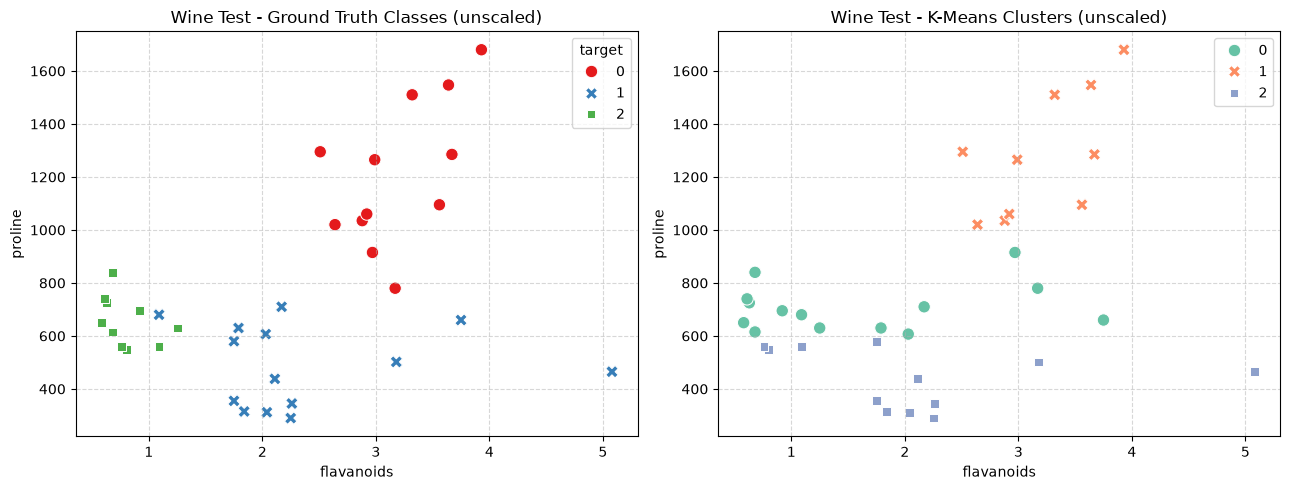


--- Representation: SCALED ---
Test ARI: 0.9088 | Test Silhouette: 0.2711


Cluster ID,0,1,2
True Class,,,
0,12,0,0
1,1,13,0
2,0,0,10


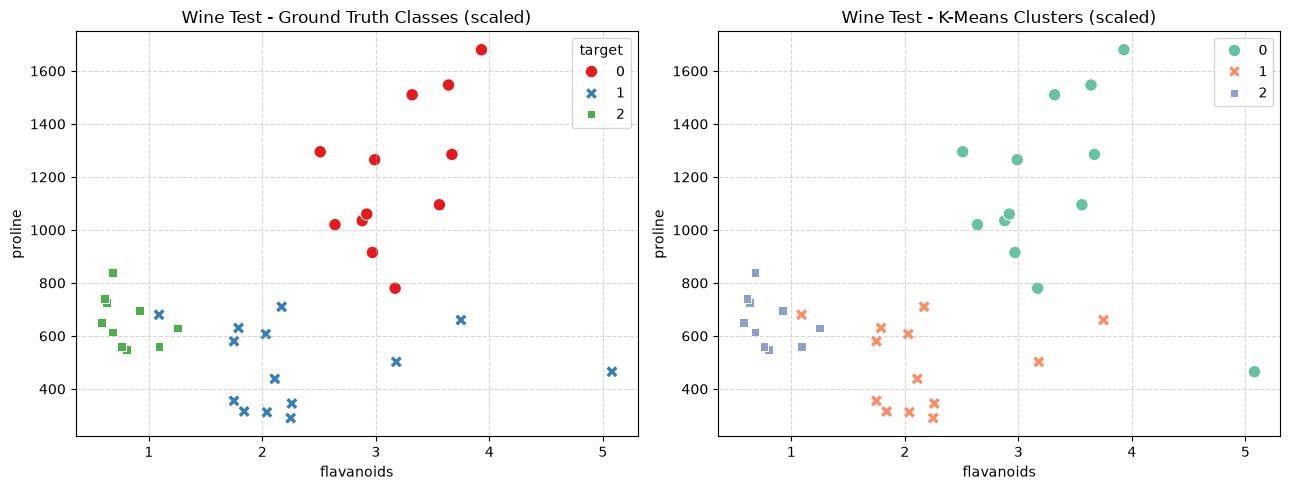

In [ ]:

# K-MEANS CLUSTERING ANALYSIS (WINE)

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

os.makedirs('figures', exist_ok=True)
kmeans_runs = []

#   K-Means Fit (Scaled & Unscaled x 3 Seeds, K=3)
for seed in SEEDS:
    X_tr = splits[seed]['X_train']
    y_tr = splits[seed]['y_train']
    X_va = splits[seed]['X_val']
    y_va = splits[seed]['y_val']
    
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_va_scaled = scaler.transform(X_va)
    
    reps = {
        'unscaled': (X_tr, X_va),
        'scaled': (X_tr_scaled, X_va_scaled)
    }
    
    for rep_name, (X_t, X_v) in reps.items():
        run_id = f"wine_kmeans_{rep_name}_k3_s{seed}"
        kmeans = KMeans(n_clusters=3, n_init=10, random_state=seed)
        kmeans.fit(X_t)  # y_tr verilmez (Unsupervised)
        
        val_clusters = kmeans.predict(X_v)
        
        kmeans_runs.append({
            'run_id': run_id,
            'dataset': 'Wine',
            'seed': seed,
            'representation': rep_name,
            'n_clusters': 3,
            'train_inertia': round(kmeans.inertia_, 4),
            'val_ari': round(adjusted_rand_score(y_va, val_clusters), 4),
            'val_silhouette': round(silhouette_score(X_v, val_clusters), 4)
        })

df_kmeans_runs = pd.DataFrame(kmeans_runs)
print("=== WINE K-MEANS RUNS (6 FITS) ===")
display(df_kmeans_runs)

# K-Means Summary Table across seeds
kmeans_summary = df_kmeans_runs.groupby(['dataset', 'representation']).agg(
    mean_train_inertia=('train_inertia', 'mean'),
    std_train_inertia=('train_inertia', lambda x: x.std(ddof=1)),
    mean_val_ari=('val_ari', 'mean'),
    std_val_ari=('val_ari', lambda x: x.std(ddof=1)),
    mean_val_silhouette=('val_silhouette', 'mean'),
    std_val_silhouette=('val_silhouette', lambda x: x.std(ddof=1))
).reset_index()

print("\n=== WINE K-MEANS SUMMARY TABLE ===")
display(kmeans_summary)

#  Seed 42 Test Cluster Evaluation & Contingency Tables
X_tr_42 = splits[42]['X_train']
y_tr_42 = splits[42]['y_train']
X_te_42 = splits[42]['X_test']
y_te_42 = splits[42]['y_test']

scaler_42 = StandardScaler()
X_tr_42_scaled = scaler_42.fit_transform(X_tr_42)
X_te_42_scaled = scaler_42.transform(X_te_42)

test_reps = {
    'unscaled': (X_tr_42, X_te_42),
    'scaled': (X_tr_42_scaled, X_te_42_scaled)
}

print("\n" + "="*50)
print("WINE K-MEANS TEST CONTINGENCY TABLES (SEED 42)")
print("="*50)

for rep_name, (X_t, X_te) in test_reps.items():
    km = KMeans(n_clusters=3, n_init=10, random_state=42)
    km.fit(X_t)
    test_clusters = km.predict(X_te)
    
    contingency = pd.crosstab(y_te_42, test_clusters, rownames=['True Class'], colnames=['Cluster ID'])
    test_ari = adjusted_rand_score(y_te_42, test_clusters)
    test_sil = silhouette_score(X_te, test_clusters)
    
    print(f"\n--- Representation: {rep_name.upper()} ---")
    print(f"Test ARI: {test_ari:.4f} | Test Silhouette: {test_sil:.4f}")
    display(contingency)
    
    # Paired Visualizations (True Classes vs Predicted Clusters)
    # Feature 0: 'flavanoids', Feature 1: 'proline' 
    feat_x = 'flavanoids'
    feat_y = 'proline'
    
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    
    #  True Classes
    sns.scatterplot(
        data=splits[42]['X_test'], x=feat_x, y=feat_y, hue=y_te_42,
        palette='Set1', style=y_te_42, s=80, ax=axes[0]
    )
    axes[0].set_title(f'Wine Test - Ground Truth Classes ({rep_name})')
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    #  Predicted Clusters
    sns.scatterplot(
        data=splits[42]['X_test'], x=feat_x, y=feat_y, hue=test_clusters,
        palette='Set2', style=test_clusters, s=80, ax=axes[1]
    )
    axes[1].set_title(f'Wine Test - K-Means Clusters ({rep_name})')
    axes[1].grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.savefig(f'figures/wine_kmeans_paired_{rep_name}.png')
    plt.show()

In [ ]:

# 12.2 EXPORTING CSV RESULT FILES (WINE)

import os
import pandas as pd

os.makedirs('csv_results', exist_ok=True)

#  classifier_runs.csv (Wine sonuçlarını kaydetme)
df_classifier_runs.to_csv('csv_results/wine_classifier_runs.csv', index=False)

# classifier_summary.csv
classifier_summary.to_csv('csv_results/wine_classifier_summary.csv', index=False)

#  classifier_test.csv 
df_classifier_test = pd.DataFrame([{
    'dataset': 'Wine',
    'selected_configuration': f"{best_config['algorithm']}_{best_config['representation']}_{best_config['parameter']}",
    'evaluation_seed': 42,
    'mean_val_f1': best_config['mean_val_f1'],
    'std_val_f1': best_config['std_val_f1'],
    'test_acc': round(test_acc, 4),
    'test_precision': round(test_prec, 4),
    'test_recall': round(test_rec, 4),
    'test_f1': round(test_f1, 4),
    'test_roc_auc': round(test_roc_auc, 4)
}])
df_classifier_test.to_csv('csv_results/wine_classifier_test.csv', index=False)

# kmeans_runs.csv
df_kmeans_runs.to_csv('csv_results/wine_kmeans_runs.csv', index=False)

#  kmeans_summary.csv
kmeans_summary.to_csv('csv_results/wine_kmeans_summary.csv', index=False)

#  kmeans_test.csv (Seed 42 Test Kümeleme Sonuçları)
kmeans_test_results = []
for rep_name, (X_t, X_te) in test_reps.items():
    km = KMeans(n_clusters=3, n_init=10, random_state=42)
    km.fit(X_t)
    test_clusters = km.predict(X_te)
    kmeans_test_results.append({
        'dataset': 'Wine',
        'representation': rep_name,
        'evaluation_seed': 42,
        'n_clusters': 3,
        'test_ari': round(adjusted_rand_score(y_te_42, test_clusters), 4),
        'test_silhouette': round(silhouette_score(X_te, test_clusters), 4)
    })
df_kmeans_test = pd.DataFrame(kmeans_test_results)
df_kmeans_test.to_csv('csv_results/wine_kmeans_test.csv', index=False)

print("=== WINE CSV FILES EXPORTED SUCCESSFULLY TO 'csv_results/' ===")

=== WINE CSV FILES EXPORTED SUCCESSFULLY TO 'csv_results/' ===


In [ ]:

# COMBINING CSV RESULTS FOR FINAL SUBMISSION

import os
import pandas as pd

os.makedirs('csv_results', exist_ok=True)
csv_files = [
    'classifier_runs',
    'classifier_summary',
    'classifier_test',
    'kmeans_runs',
    'kmeans_summary',
    'kmeans_test'
]

for filename in csv_files:
    bc_path = f'csv_results/breast_cancer_{filename}.csv'
    wine_path = f'csv_results/wine_{filename}.csv'
    output_path = f'{filename}.csv'  # Proje ana dizinine kaydeder
    
    if os.path.exists(bc_path) and os.path.exists(wine_path):
        df_bc = pd.read_csv(bc_path)
        df_wine = pd.read_csv(wine_path)
        df_combined = pd.concat([df_bc, df_wine], ignore_index=True)
        df_combined.to_csv(output_path, index=False)
        print(f"Created: {output_path} (Rows: {len(df_combined)})")

print("\n=== ALL 6 MAIN CSV FILES COMBINED SUCCESSFULLY! ===")

Created: classifier_runs.csv (Rows: 132)
Created: classifier_summary.csv (Rows: 44)
Created: classifier_test.csv (Rows: 2)
Created: kmeans_runs.csv (Rows: 12)
Created: kmeans_summary.csv (Rows: 4)
Created: kmeans_test.csv (Rows: 4)

=== ALL 6 MAIN CSV FILES COMBINED SUCCESSFULLY! ===
